# SmartRoad Preditiva — esta ocorrência vai demorar mais de 30 dias?

**Global Solution 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**
**CitizenTech:** SmartRoad (app em que o morador de São Paulo registra e acompanha buracos, bueiros e calçadas danificadas)

| Etapa do percurso | Onde está neste notebook |
| --- | --- |
| 01 · Problema e dados reais | Seções 1 e 2 |
| 02 · Modelo e preparação | Seções 3 e 4 |
| 03 · Treino e avaliação | Seção 5 |
| 04 · Resultados e conclusão | Seções 6 e 7 |

## 1. O problema da CitizenTech virou uma pergunta de Machine Learning

No SmartRoad o cidadão registra um problema da rua e acompanha o andamento (Recebida → Em andamento → Concluída). O que o app **não** consegue dizer hoje é a primeira coisa que o morador quer saber: *"isso vai demorar?"*. O indicador de impacto da nossa Ficha é justamente o tempo entre o registro e a conclusão.

**Pergunta de ML:** no momento em que uma ocorrência de zeladoria é registrada, dá para prever se ela vai **demorar mais de 30 dias para ser finalizada**?

- **Tipo de problema:** classificação binária supervisionada.
- **Alvo (`demora`):** 1 = a solicitação não foi finalizada em até 30 dias; 0 = foi finalizada em até 30 dias.
- **Entradas:** só o que o app sabe na hora do registro (tipo de serviço, canal, região, coordenadas e data).
- **Dados:** solicitações reais feitas à Prefeitura de São Paulo pelo SP156 (nada simulado).

In [1]:
# Bibliotecas (versões em ml/requirements.txt)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from xgboost import XGBClassifier

SEMENTE = 42  # mesma semente em tudo, para o resultado se repetir

# Padrão visual dos gráficos: azul = treino, laranja = teste/validação, grade discreta.
AZUL, LARANJA, CINZA, TEXTO = "#2a78d6", "#eb6834", "#8a8983", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})
PASTA_FIGURAS = Path("figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

## 2. Dados reais e públicos: SP156

| | |
| --- | --- |
| **Fonte** | Portal de Dados Abertos da Prefeitura de São Paulo — conjunto "Dados do SP156 - Solicitações" |
| **Link** | https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 |
| **Período** | solicitações abertas de **01/07/2025 a 30/06/2026** (arquivos do 3º e 4º trimestres de 2025 e do 1º e 2º de 2026) |
| **Situação dos dados** | os quatro arquivos foram republicados pela Prefeitura em 10/08/2026; o status e a data de finalização valem até essa extração |
| **Licença** | Creative Commons CC0 (domínio público) |
| **Baixado em** | 14/11/2026 |

Os quatro arquivos originais somam cerca de 430 MB e 2 milhões de solicitações de todos os assuntos (trânsito, lixo, saúde...). O script `dados/preparar_dados.py` baixa esses arquivos e guarda só o que interessa ao SmartRoad: os **9 serviços** que correspondem aos tipos de ocorrência do app. Ele só filtra linhas e colunas; nenhum valor é alterado. Detalhes em `dados/README.md`.

| Tipo no SmartRoad | Serviços do SP156 |
| --- | --- |
| Buraco | Tapa-buraco · Tapa-buraco em faixa exclusiva ou corredor de ônibus |
| Bueiro quebrado | Limpeza de bueiros, boca de lobo e poços de visita · Drenagem: bueiros e bocas de lobo · Reformar galerias de águas de chuva |
| Calçada danificada | Calçada pública: manutenção · Calçada particular danificada ou inexistente · Obstáculo na calçada (acessibilidade) · Guias, sarjetas e sarjetões: manutenção |
| Iluminação | *não existe serviço de iluminação pública nos arquivos do SP156 deste período, então fica fora do modelo* |

In [2]:
# Leitura do recorte. Fora do repositório (ex.: Google Colab), lê o mesmo arquivo direto do GitHub.
ARQUIVO = Path("dados/sp156_zeladoria_jul2025_jun2026.csv.gz")
URL = "https://raw.githubusercontent.com/MAJE-Dev/SmartRoad-Preditiva/main/ml/dados/sp156_zeladoria_jul2025_jun2026.csv.gz"

bruto = pd.read_csv(ARQUIVO if ARQUIVO.exists() else URL, dtype=str)

print(f"Linhas: {len(bruto):,} | Colunas: {bruto.shape[1]}")
bruto.head()

Linhas: 189,467 | Colunas: 11


,tipo_smartroad,data_abertura,data_finalizacao,canal,servico,status,orgao,latitude,longitude,subprefeitura,distrito
0,Buraco,01/07/2025,15/07/2025,MOBILE,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.6843931,-46.7703849,M BOI MIRIM,JARDIM ANGELA
1,Buraco,01/07/2025,04/07/2025,MOBILE,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5380607,-46.7252154,PINHEIROS,ALTO DE PINHEIROS
2,Calçada,01/07/2025,23/12/2025,CHATBOT,"Guias, sarjetas e sarjetões - solicitar manutenção",Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.6738969,-46.73938709999999,M BOI MIRIM,JARDIM SAO LUIS
3,Buraco,01/07/2025,12/08/2025,PORTAL,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5534612,-46.73729770000001,LAPA,JAGUARE
4,Buraco,01/07/2025,05/07/2025,MOBILE,Tapa-buraco,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.5410186,-46.7247937,PINHEIROS,ALTO DE PINHEIROS


In [3]:
# Auditoria inicial: valores vazios e categorias de cada coluna
auditoria = pd.DataFrame({
    "vazios": bruto.isna().sum(),
    "% vazios": (bruto.isna().mean() * 100).round(1),
    "valores distintos": bruto.nunique(),
})
display(auditoria)

print("Status das solicitações na data da extração:")
display(bruto["status"].value_counts().to_frame("solicitações"))

,vazios,% vazios,valores distintos
tipo_smartroad,0,0.0,3
data_abertura,0,0.0,365
data_finalizacao,42161,22.3,401
canal,0,0.0,5
servico,0,0.0,9
status,0,0.0,4
orgao,0,0.0,8
latitude,2,0.0,132253
longitude,2,0.0,131107
subprefeitura,357,0.2,38


Status das solicitações na data da extração:


,solicitações
status,
Finalizada,146107
Aberto,42133
Cancelada,1225
Em Andamento,2


**O que a auditoria mostra**

- A única coluna com muitos vazios é `data_finalizacao`. Isso é esperado: são as solicitações que ainda estavam abertas na extração. Essa informação vira o nosso alvo, não um defeito a corrigir.
- `status` e `data_finalizacao` são a "resposta" do problema. `orgao` é o órgão responsável **na data da extração** e, segundo o dicionário do SP156, pode mudar depois da abertura. Nenhuma dessas três colunas pode entrar como entrada do modelo: seria vazamento de informação do futuro.

## 3. Preparação dos dados

### 3.1 Limpeza

Cada passo abaixo remove ou corrige um problema específico, e a tabela no final mostra quantas linhas saíram em cada um.

In [4]:
dados = bruto.copy()
funil = {"Recorte original": len(dados)}

# 1) Tipos: datas (dd/mm/aaaa) e coordenadas viram data e número
dados["data_abertura"] = pd.to_datetime(dados["data_abertura"], format="%d/%m/%Y")
dados["data_finalizacao"] = pd.to_datetime(dados["data_finalizacao"], format="%d/%m/%Y")
dados["latitude"] = pd.to_numeric(dados["latitude"])
dados["longitude"] = pd.to_numeric(dados["longitude"])

# 2) Canceladas: quem cancelou foi o cidadão, então não dizem nada sobre o tempo da Prefeitura
dados = dados[dados["status"] != "Cancelada"]
funil["Sem as canceladas pelo cidadão"] = len(dados)

# 3) "Finalizada" sem data de finalização: não dá para calcular o tempo
dados = dados[~((dados["status"] == "Finalizada") & dados["data_finalizacao"].isna())]
funil["Sem finalizadas sem data"] = len(dados)

# 4) Canal "RESOLUCAO": só 20 linhas, e não está entre os canais de atendimento descritos no dicionário
dados = dados[dados["canal"] != "RESOLUCAO"]
funil["Sem o canal RESOLUCAO"] = len(dados)

# 5) Coordenadas fora do município de São Paulo (erro de cadastro, como latitude 0)
dentro_de_sp = dados["latitude"].between(-24.1, -23.3) & dados["longitude"].between(-46.9, -46.3)
dados = dados[dentro_de_sp]
funil["Com coordenadas dentro de São Paulo"] = len(dados)

# 6) Subprefeitura: duas mudaram de nome no meio do período; valores que não são região viram uma categoria só
dados["subprefeitura"] = dados["subprefeitura"].replace({
    "CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA",
    "PERUS-ANHANGUERA": "PERUS",
})
NAO_E_REGIAO = ["Superintendencia das Usinas de Asfalto", "Prefeitura Regional nao encontrada",
                "Departamento de Aguas e Energia Eletrica", "Secretaria Municipal do Verde e do Meio Ambiente"]
dados["subprefeitura"] = dados["subprefeitura"].replace(NAO_E_REGIAO, "NAO IDENTIFICADA").fillna("NAO IDENTIFICADA")

dados = dados.sort_values("data_abertura").reset_index(drop=True)

funil = pd.Series(funil, name="linhas").to_frame()
funil["removidas no passo"] = -funil["linhas"].diff().fillna(0).astype(int)
display(funil)

# Conferências: 32 subprefeituras de São Paulo + "NAO IDENTIFICADA", nenhuma data invertida
assert dados["subprefeitura"].nunique() == 33
assert (dados["data_finalizacao"].dropna() >= dados.loc[dados["data_finalizacao"].notna(), "data_abertura"]).all()
print(f"Ficaram {len(dados):,} solicitações ({len(dados) / len(bruto):.1%} do recorte).")

,linhas,removidas no passo
Recorte original,189467,0
Sem as canceladas pelo cidadão,188242,1225
Sem finalizadas sem data,188216,26
Sem o canal RESOLUCAO,188196,20
Com coordenadas dentro de São Paulo,188136,60


Ficaram 188,136 solicitações (99.3% do recorte).


### 3.2 Construção do alvo

`dias_ate_finalizar` é a diferença entre a data de finalização e a de abertura. O alvo `demora` vale 1 quando a solicitação **não** foi finalizada em até 30 dias, o que inclui as que continuavam abertas na extração.

**Por que 30 dias?** A última solicitação do recorte foi aberta em 30/06/2026 e os arquivos trazem finalizações até a primeira semana de agosto de 2026. Ou seja, toda solicitação foi observada por pelo menos 30 dias, e o alvo é conhecido para 100% das linhas. Se o alvo fosse "quantos dias demorou", teríamos que jogar fora as solicitações ainda abertas, que são justamente as mais demoradas, e o modelo aprenderia uma cidade mais rápida do que a real.

In [5]:
dados["dias_ate_finalizar"] = (dados["data_finalizacao"] - dados["data_abertura"]).dt.days
dados["demora"] = (~(dados["dias_ate_finalizar"] <= 30)).astype(int)  # ainda aberta (vazio) também conta como demora

# Toda solicitação teve pelo menos 30 dias para ser finalizada antes da extração?
ultima_abertura = dados["data_abertura"].max()
ultima_finalizacao = dados["data_finalizacao"].max()
print(f"Última abertura: {ultima_abertura:%d/%m/%Y} | última finalização registrada: {ultima_finalizacao:%d/%m/%Y}")
assert (ultima_finalizacao - ultima_abertura).days >= 30

resumo_alvo = dados["demora"].map({0: "0 · finalizada em até 30 dias", 1: "1 · demora mais de 30 dias"}).value_counts().to_frame("solicitações")
resumo_alvo["%"] = (resumo_alvo["solicitações"] / len(dados) * 100).round(1)
display(resumo_alvo)
print(f"Entre as finalizadas, metade fecha em até {dados['dias_ate_finalizar'].median():.0f} dias.")

Última abertura: 30/06/2026 | última finalização registrada: 07/08/2026


,solicitações,%
demora,,
0 · finalizada em até 30 dias,119185,63.4
1 · demora mais de 30 dias,68951,36.6


Entre as finalizadas, metade fecha em até 7 dias.


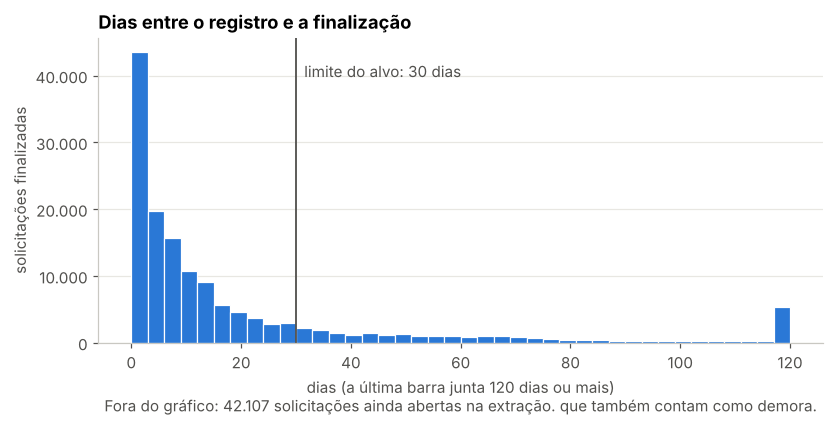

In [6]:
# Como o tempo até a finalização se distribui (só as finalizadas têm tempo conhecido)
finalizadas = dados["dias_ate_finalizar"].dropna()
abertas = dados["dias_ate_finalizar"].isna().sum()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(finalizadas.clip(upper=120), bins=range(0, 123, 3), color=AZUL, edgecolor="white", linewidth=0.8)
ax.axvline(30, color=TEXTO, linewidth=1.2)
ax.text(31.5, ax.get_ylim()[1] * 0.92, "limite do alvo: 30 dias", color=TEXTO, va="top")
ax.set_title("Dias entre o registro e a finalização")
ax.set_xlabel("dias (a última barra junta 120 dias ou mais)\n"
              + f"Fora do gráfico: {abertas:,} solicitações ainda abertas na extração, que também contam como demora.".replace(",", "."))
ax.set_ylabel("solicitações finalizadas")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "01_dias_ate_finalizar.png")
plt.show()

### 3.3 O que os dados já contam antes do modelo

Antes de treinar, olhamos como a taxa de demora muda conforme o serviço e conforme o mês de abertura. Isso ajuda a escolher as entradas e, principalmente, a forma de dividir treino e teste.

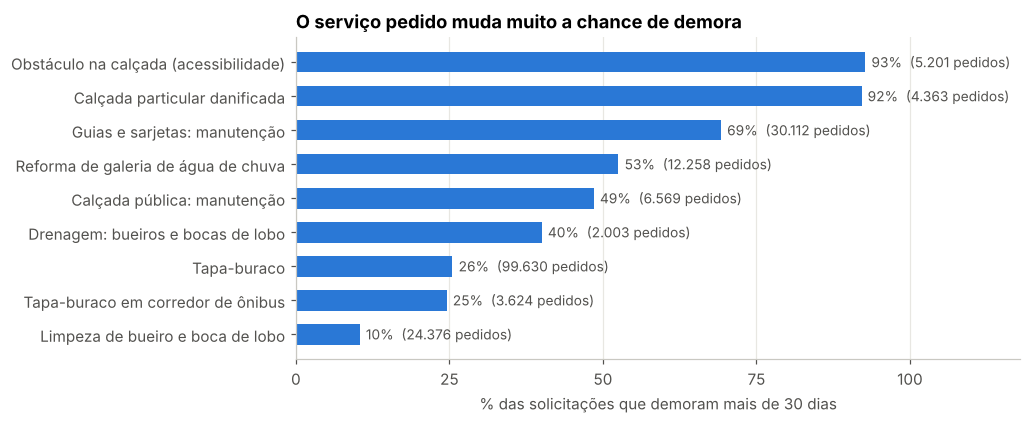

In [7]:
# Nomes curtos para os gráficos (os nomes oficiais do SP156 são longos)
NOME_CURTO = {
    "Tapa-buraco": "Tapa-buraco",
    "Tapa-buraco em faixa exclusiva ou corredor de ônibus": "Tapa-buraco em corredor de ônibus",
    "Solicitar limpeza de bueiros, boca de lobo e poços de visita": "Limpeza de bueiro e boca de lobo",
    "Drenagem de água da chuva - Bueiros e bocas de lobo": "Drenagem: bueiros e bocas de lobo",
    "Reformar galerias de águas de chuvas (pluviais)": "Reforma de galeria de água de chuva",
    "Calçada pública - solicitar manutenção": "Calçada pública: manutenção",
    "Calçada particular - denunciar calçada danificada ou inexistente": "Calçada particular danificada",
    "Acessibilidade - solicitar avaliação de obstáculo na calçada": "Obstáculo na calçada (acessibilidade)",
    "Guias, sarjetas e sarjetões - solicitar manutenção": "Guias e sarjetas: manutenção",
}

por_servico = dados.groupby("servico")["demora"].agg(taxa="mean", solicitacoes="size").sort_values("taxa")
por_servico.index = por_servico.index.map(NOME_CURTO)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
barras = ax.barh(por_servico.index, por_servico["taxa"] * 100, color=AZUL, height=0.6)
for barra, (taxa, n) in zip(barras, por_servico.itertuples(index=False)):
    ax.text(barra.get_width() + 1, barra.get_y() + barra.get_height() / 2,
            f"{taxa:.0%}  ({n:,} pedidos)".replace(",", "."), va="center", color=TEXTO, fontsize=9)
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_title("O serviço pedido muda muito a chance de demora")
ax.set_xlabel("% das solicitações que demoram mais de 30 dias")
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "02_demora_por_servico.png")
plt.show()

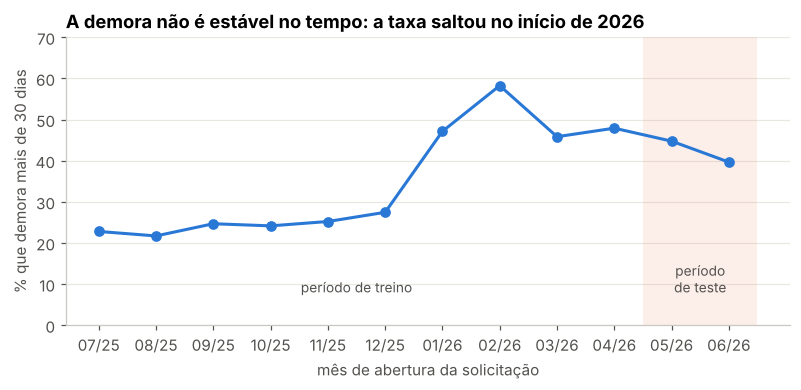

In [8]:
# Taxa de demora por mês de abertura
por_mes = dados.groupby(dados["data_abertura"].dt.to_period("M"))["demora"].mean() * 100
rotulos = [f"{p.month:02d}/{str(p.year)[2:]}" for p in por_mes.index]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(rotulos, por_mes.values, color=AZUL, marker="o", markersize=6)
ax.axvspan(9.5, 11.5, color=LARANJA, alpha=0.10, linewidth=0)
ax.text(10.5, 8, "período\nde teste", ha="center", color=TEXTO, fontsize=9)
ax.text(4.5, 8, "período de treino", ha="center", color=TEXTO, fontsize=9)
ax.set_ylim(0, 70)
ax.set_title("A demora não é estável no tempo: a taxa saltou no início de 2026")
ax.set_xlabel("mês de abertura da solicitação")
ax.set_ylabel("% que demora mais de 30 dias")
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "03_demora_por_mes.png")
plt.show()

In [9]:
# E a região? As 3 subprefeituras com menor e as 3 com maior taxa de demora
por_regiao = dados[dados["subprefeitura"] != "NAO IDENTIFICADA"].groupby("subprefeitura")["demora"].agg(
    taxa_de_demora="mean", solicitacoes="size").sort_values("taxa_de_demora")
por_regiao["taxa_de_demora"] = (por_regiao["taxa_de_demora"] * 100).round(1)
pd.concat([por_regiao.head(3), por_regiao.tail(3)])

,taxa_de_demora,solicitacoes
subprefeitura,,
PERUS,22.4,2899
ERMELINO MATARAZZO,22.4,3269
SAO MIGUEL,25.7,5670
SANTANA-TUCURUVI,47.8,5967
CASA VERDE-CACHOEIRINHA,48.7,4492
SE,50.3,7699


**Leitura dos gráficos**

- O **serviço** é o que mais separa os casos: limpeza de bueiro quase sempre fecha em 30 dias; denúncia de calçada particular e obstáculo na calçada quase nunca.
- A taxa de demora **muda com o tempo**: ficou perto de 25% no segundo semestre de 2025 e subiu para a faixa de 40% a 60% em 2026. O modelo vai ser usado para prever ocorrências **futuras**, então precisa ser testado em meses que ele não viu. É por isso que a divisão treino/teste abaixo é feita **por data**, e não por sorteio.

### 3.4 Entradas do modelo

Entram só informações que o SmartRoad tem **no momento do registro**:

| Entrada | Tipo | De onde vem no app |
| --- | --- | --- |
| `servico` | categórica (9) | tipo de ocorrência escolhido pelo cidadão |
| `canal` | categórica (4) | por onde o pedido chega (no SP156: MOBILE, PORTAL, CRM e CHATBOT; no SmartRoad seria sempre o app) |
| `subprefeitura` | categórica (33) | região da cidade, a partir da localização |
| `latitude`, `longitude` | numéricas | GPS do celular ou endereço |
| `mes`, `dia_semana` | numéricas | data do registro |

Ficam **de fora**: `status`, `data_finalizacao` e `dias_ate_finalizar` (são a resposta), `orgao` (pode mudar depois da abertura) e `distrito` (96 categorias que a latitude e a longitude já representam).

As variáveis categóricas passam por *one-hot encoding* (uma coluna 0/1 por categoria), como fizemos nos trabalhos do primeiro semestre.

In [10]:
dados["mes"] = dados["data_abertura"].dt.month
dados["dia_semana"] = dados["data_abertura"].dt.dayofweek  # 0 = segunda ... 6 = domingo

NUMERICAS = ["latitude", "longitude", "mes", "dia_semana"]
CATEGORICAS = ["servico", "canal", "subprefeitura"]

X = pd.get_dummies(dados[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)
y = dados["demora"]

assert len(X) == len(dados) and X.isna().sum().sum() == 0  # nenhuma linha perdida, nenhum vazio
print(f"Matriz de entradas: {X.shape[0]:,} linhas x {X.shape[1]} colunas (4 numéricas + {X.shape[1] - 4} colunas 0/1)")

Matriz de entradas: 188,136 linhas x 50 colunas (4 numéricas + 46 colunas 0/1)


### 3.5 Divisão treino / teste (por data)

- **Treino:** solicitações abertas de 01/07/2025 a 30/04/2026 (10 meses).
- **Teste:** solicitações abertas de 01/05/2026 a 30/06/2026 (os 2 meses mais recentes).

O teste fica guardado até a Seção 6. Toda escolha de hiperparâmetro é feita só com o treino.

In [11]:
CORTE = pd.Timestamp("2026-05-01")
no_treino = dados["data_abertura"] < CORTE

X_treino, y_treino = X[no_treino], y[no_treino]
X_teste, y_teste = X[~no_treino], y[~no_treino]

divisao = pd.DataFrame({
    "período": ["01/07/2025 a 30/04/2026", "01/05/2026 a 30/06/2026"],
    "solicitações": [len(X_treino), len(X_teste)],
    "% do total": [round(len(X_treino) / len(X) * 100, 1), round(len(X_teste) / len(X) * 100, 1)],
    "% que demora": [round(y_treino.mean() * 100, 1), round(y_teste.mean() * 100, 1)],
}, index=["treino", "teste"])
display(divisao)

# Nenhuma solicitação do teste é anterior à última do treino
assert dados.loc[no_treino, "data_abertura"].max() < dados.loc[~no_treino, "data_abertura"].min()

,período,solicitações,% do total,% que demora
treino,01/07/2025 a 30/04/2026,161677,85.9,35.8
teste,01/05/2026 a 30/06/2026,26459,14.1,42.1


## 4. Escolha do modelo: XGBoost

Entre as opções do enunciado (XGBoost, Random Forest, MLP, LSTM e KMeans + PCA), escolhemos o **XGBoost** (`XGBClassifier`):

- **Os dados são uma tabela** com variáveis categóricas e numéricas misturadas. Modelos de árvores costumam ser os melhores nesse formato e não exigem normalizar nada.
- **As relações não são lineares e se combinam**: o efeito da região depende do serviço e da época. Árvores capturam essas combinações sozinhas; a latitude e a longitude, por exemplo, viram "recortes" do mapa.
- **Temos rótulo**, então é um problema supervisionado. KMeans + PCA agrupa sem usar a resposta e não responde "vai demorar?".
- **Não há uma sequência longa por ocorrência**: cada linha é um pedido independente, então uma LSTM não tem o que aproveitar. Uma MLP exigiria normalização e mais ajuste para, em tabelas assim, normalmente empatar ou perder para árvores.
- **Contra o Random Forest**, o XGBoost constrói as árvores em sequência, cada uma corrigindo os erros das anteriores, e tem controles diretos de complexidade (profundidade, taxa de aprendizado, número de árvores). Isso é útil aqui, porque o maior risco do problema é o modelo decorar o passado.
- Ele devolve uma **probabilidade**, que é o que o app precisa mostrar ao cidadão ("chance alta de demorar"), e treina em segundos com 160 mil linhas.

## 5. Treino com diferentes hiperparâmetros

Testamos **18 combinações de 3 hiperparâmetros** com `GridSearchCV`:

| Hiperparâmetro | Valores | O que controla |
| --- | --- | --- |
| `max_depth` | 3, 6, 9 | profundidade de cada árvore (quanto maior, mais detalhe e mais risco de decorar) |
| `learning_rate` | 0,03 · 0,1 · 0,3 | tamanho do passo de cada árvore nova |
| `n_estimators` | 100, 300 | quantidade de árvores |

**Validação cruzada só no treino.** Usamos `TimeSeriesSplit` com 4 divisões: o treino é cortado em 5 blocos em ordem de data e, em cada rodada, o modelo treina nos blocos mais antigos e é validado no bloco seguinte. É a mesma lógica da divisão treino/teste (aprender com o passado, prever o futuro), e o conjunto de teste não participa.

**Métrica da busca:** AUC-ROC, que mede se o modelo dá probabilidade maior para as solicitações que realmente demoram. Ela não depende de um ponto de corte e não se deixa enganar pela mudança na proporção de demoras ao longo do tempo.

In [12]:
grade = {
    "max_depth": [3, 6, 9],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [100, 300],
}

busca = GridSearchCV(
    estimator=XGBClassifier(tree_method="hist", random_state=SEMENTE, n_jobs=4),
    param_grid=grade,
    scoring="roc_auc",
    cv=TimeSeriesSplit(n_splits=4),   # só dentro do treino, sempre validando em datas posteriores
    return_train_score=True,          # guarda também a nota no treino, para medir o overfitting
)
busca.fit(X_treino, y_treino)

print(f"Combinações testadas: {len(busca.cv_results_['params'])} (x 4 divisões = {len(busca.cv_results_['params']) * 4} treinos)")
print(f"Melhor combinação: {busca.best_params_} | AUC média na validação: {busca.best_score_:.3f}")

Combinações testadas: 18 (x 4 divisões = 72 treinos)
Melhor combinação: {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 100} | AUC média na validação: 0.800


In [13]:
# Todas as combinações, da melhor para a pior na validação
resultados = pd.DataFrame(busca.cv_results_["params"])
resultados["AUC treino"] = busca.cv_results_["mean_train_score"]
resultados["AUC validação"] = busca.cv_results_["mean_test_score"]
resultados["desvio validação"] = busca.cv_results_["std_test_score"]
resultados["diferença (treino - validação)"] = resultados["AUC treino"] - resultados["AUC validação"]
resultados = resultados.sort_values("AUC validação", ascending=False).reset_index(drop=True)
resultados.index += 1
resultados.round(3)

,learning_rate,max_depth,n_estimators,AUC treino,AUC validação,desvio validação,diferença (treino - validação)
1,0.10,9,100,0.945,0.800,0.044,0.145
2,0.03,9,300,0.942,0.800,0.044,0.143
3,0.10,6,300,0.937,0.799,0.044,0.138
4,0.30,6,100,0.939,0.799,0.043,0.140
5,0.03,9,100,0.926,0.798,0.048,0.128
6,0.10,6,100,0.919,0.798,0.048,0.121
7,0.03,6,300,0.917,0.798,0.049,0.119
8,0.30,3,300,0.919,0.797,0.043,0.122
9,0.03,6,100,0.905,0.796,0.054,0.109
10,0.10,9,300,0.969,0.795,0.039,0.173


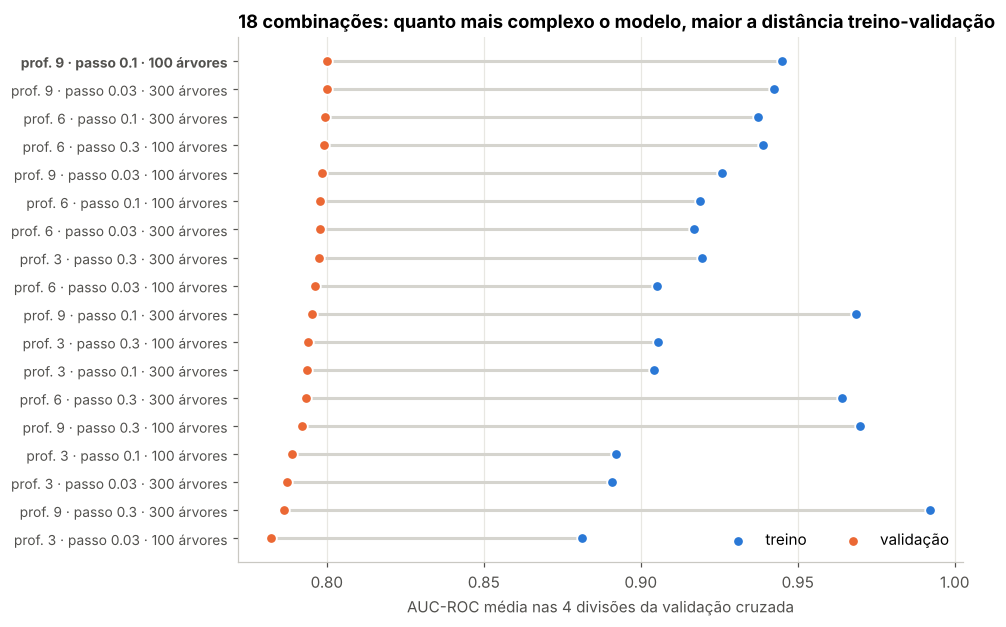

In [14]:
# Treino x validação em cada combinação: a distância entre os pontos é o overfitting
ordem = resultados.iloc[::-1]
nomes = [f"prof. {int(p)} · passo {t} · {int(n)} árvores"
         for p, t, n in zip(ordem["max_depth"], ordem["learning_rate"], ordem["n_estimators"])]
posicoes = np.arange(len(ordem))

fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.hlines(posicoes, ordem["AUC validação"], ordem["AUC treino"], color="#d5d4ce", linewidth=2, zorder=1)
ax.scatter(ordem["AUC treino"], posicoes, color=AZUL, s=48, zorder=2, edgecolor="white", linewidth=1.2, label="treino")
ax.scatter(ordem["AUC validação"], posicoes, color=LARANJA, s=48, zorder=2, edgecolor="white", linewidth=1.2, label="validação")
ax.set_yticks(posicoes, nomes, fontsize=9)
ax.get_yticklabels()[-1].set_fontweight("bold")  # a escolhida fica no topo
ax.set_xlabel("AUC-ROC média nas 4 divisões da validação cruzada")
ax.set_title("18 combinações: quanto mais complexo o modelo, maior a distância treino-validação")
ax.legend(loc="lower right", ncols=2)
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "04_busca_hiperparametros.png")
plt.show()

**Leitura da busca**

- **Combinação escolhida:** `max_depth=9`, `learning_rate=0.1`, `n_estimators=100`, com AUC média de 0,800 na validação. A regra (maior AUC média na validação) foi definida antes de olhar o teste.
- **É quase um empate:** as 9 primeiras combinações ficam entre 0,796 e 0,800, uma diferença bem menor que o desvio entre as divisões (0,04 a 0,05). Qualquer uma delas serviria. O desvio é alto porque cada divisão valida em uma época diferente, e as épocas não são iguais (gráfico da Seção 3.3).
- **Dá para ver o overfitting acontecendo:** em todas as combinações o treino (0,88 a 0,99) fica bem acima da validação (0,78 a 0,80). A mais complexa da grade (profundidade 9, passo 0,3, 300 árvores) chega a 0,992 no treino e é uma das piores na validação (0,786): ela decorou o treino. A mais simples (profundidade 3, passo 0,03, 100 árvores) tem a menor distância (0,099), mas também a pior validação (0,782): aprendeu de menos.
- Aumentar a complexidade além do ponto escolhido só melhora a nota do treino. É o sinal para parar.

## 6. Resultados em treino e teste

O `GridSearchCV` já retreinou a melhor combinação com **todo** o treino. Agora, pela primeira vez, o modelo vê o conjunto de teste (maio e junho de 2026).

Métricas usadas, e por quê:

- **AUC-ROC:** qualidade da ordenação das probabilidades (0,5 = sorteio; 1,0 = perfeito).
- **Acurácia** e **acurácia balanceada:** acertos no total e a média dos acertos em cada classe. A balanceada evita a ilusão de acertar muito só por chutar a classe mais comum.
- **Precisão, recall e F1 da classe "demora":** quando o modelo avisa que vai demorar, quantas vezes acerta (precisão); das que demoraram, quantas ele avisou (recall); F1 resume as duas.
- **Linha de base:** um "modelo" que sempre responde "não vai demorar". Se o XGBoost não ganhar disso, não serve.

In [15]:
modelo = busca.best_estimator_

def avaliar(X_parte, y_parte):
    # Calcula todas as métricas de uma parte (treino ou teste) com ponto de corte de 50%
    prob = modelo.predict_proba(X_parte)[:, 1]
    previsto = (prob >= 0.5).astype(int)
    return {
        "AUC-ROC": roc_auc_score(y_parte, prob),
        "Acurácia": accuracy_score(y_parte, previsto),
        "Acurácia balanceada": balanced_accuracy_score(y_parte, previsto),
        "Precisão (demora)": precision_score(y_parte, previsto),
        "Recall (demora)": recall_score(y_parte, previsto),
        "F1 (demora)": f1_score(y_parte, previsto),
    }

metricas = pd.DataFrame({"treino": avaliar(X_treino, y_treino), "teste": avaliar(X_teste, y_teste)})
metricas["diferença"] = metricas["treino"] - metricas["teste"]

# Linha de base: responder sempre "não vai demorar"
base_treino, base_teste = 1 - y_treino.mean(), 1 - y_teste.mean()
print(f"Linha de base (sempre 'não demora'): acurácia {base_treino:.3f} no treino e {base_teste:.3f} no teste; "
      "acurácia balanceada 0.500; recall 0.000")
metricas.round(3)

Linha de base (sempre 'não demora'): acurácia 0.642 no treino e 0.579 no teste; acurácia balanceada 0.500; recall 0.000


,treino,teste,diferença
AUC-ROC,0.909,0.767,0.142
Acurácia,0.829,0.706,0.123
Acurácia balanceada,0.803,0.681,0.122
Precisão (demora),0.791,0.704,0.088
Recall (demora),0.710,0.521,0.189
F1 (demora),0.749,0.599,0.150


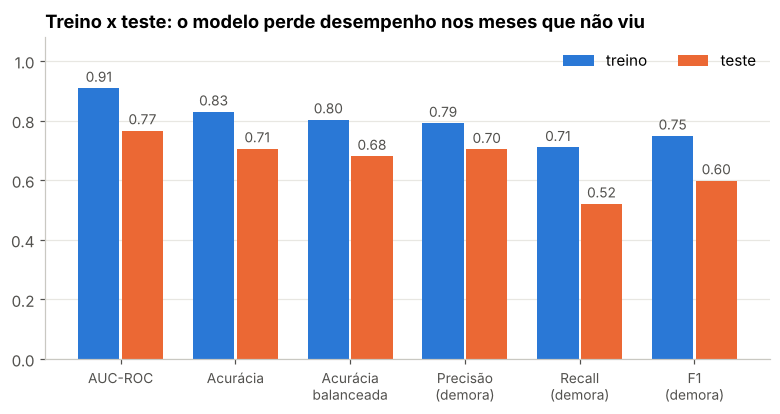

In [16]:
# Métricas de treino e teste lado a lado
fig, ax = plt.subplots(figsize=(8.5, 3.8))
posicoes = np.arange(len(metricas))
largura = 0.36
barras_treino = ax.bar(posicoes - largura / 2 - 0.01, metricas["treino"], largura, color=AZUL, label="treino")
barras_teste = ax.bar(posicoes + largura / 2 + 0.01, metricas["teste"], largura, color=LARANJA, label="teste")
for barras in (barras_treino, barras_teste):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=9, color=TEXTO)
ax.set_xticks(posicoes, [m.replace(" (", "\n(").replace("Acurácia b", "Acurácia\nb") for m in metricas.index], fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_title("Treino x teste: o modelo perde desempenho nos meses que não viu")
ax.legend(loc="upper right", ncols=2)
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "05_metricas_treino_teste.png")
plt.show()

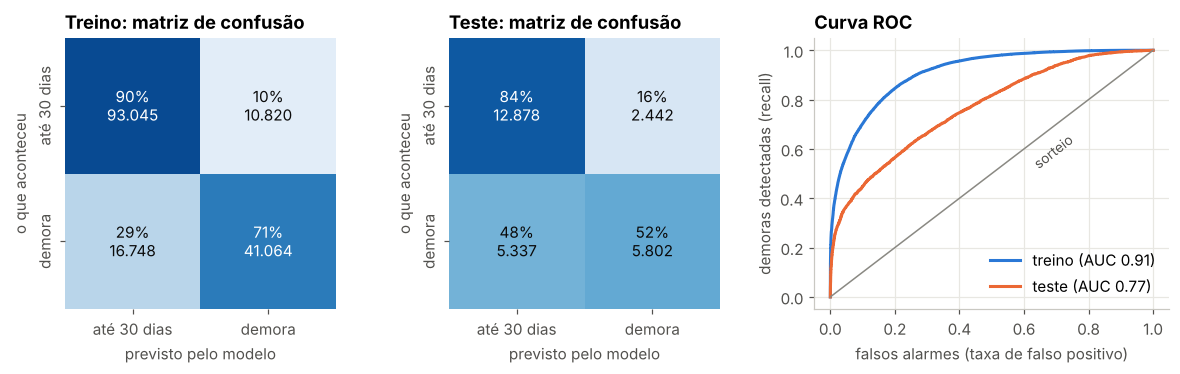

In [17]:
# Matriz de confusão (em % de cada linha) e curva ROC, treino e teste
prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.5), gridspec_kw={"width_ratios": [1, 1, 1.15]})
classes = ["até 30 dias", "demora"]
for ax, nome, y_parte, prob in [(eixos[0], "Treino", y_treino, prob_treino), (eixos[1], "Teste", y_teste, prob_teste)]:
    matriz = confusion_matrix(y_parte, (prob >= 0.5).astype(int))
    proporcao = matriz / matriz.sum(axis=1, keepdims=True)
    ax.imshow(proporcao, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{proporcao[i, j]:.0%}\n{matriz[i, j]:,}".replace(",", "."), ha="center", va="center",
                    color="white" if proporcao[i, j] > 0.55 else "#0b0b0b", fontsize=10)
    ax.set_xticks([0, 1], classes); ax.set_yticks([0, 1], classes, rotation=90, va="center")
    ax.set_xlabel("previsto pelo modelo"); ax.set_ylabel("o que aconteceu")
    ax.set_title(f"{nome}: matriz de confusão")
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)

ax = eixos[2]
for nome, y_parte, prob, cor in [("treino", y_treino, prob_treino, AZUL), ("teste", y_teste, prob_teste, LARANJA)]:
    falso_positivo, verdadeiro_positivo, _ = roc_curve(y_parte, prob)
    ax.plot(falso_positivo, verdadeiro_positivo, color=cor, label=f"{nome} (AUC {roc_auc_score(y_parte, prob):.2f})")
ax.plot([0, 1], [0, 1], color=CINZA, linewidth=1)
ax.text(0.62, 0.52, "sorteio", color=TEXTO, fontsize=9, rotation=38)
ax.set_xlabel("falsos alarmes (taxa de falso positivo)"); ax.set_ylabel("demoras detectadas (recall)")
ax.set_title("Curva ROC")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "06_confusao_e_roc.png")
plt.show()

### 6.1 Por que dividir por data? O mesmo modelo com divisão por sorteio

Só para comparação, treinamos os mesmos hiperparâmetros com uma divisão **aleatória** do mesmo tamanho. Esse número não é o resultado do trabalho: ele mostra o quanto uma divisão por sorteio enfeitaria a nota.

In [18]:
Xa_treino, Xa_teste, ya_treino, ya_teste = train_test_split(
    X, y, test_size=len(X_teste), stratify=y, random_state=SEMENTE)

modelo_sorteio = XGBClassifier(**busca.best_params_, tree_method="hist", random_state=SEMENTE, n_jobs=4)
modelo_sorteio.fit(Xa_treino, ya_treino)

comparacao = pd.DataFrame({
    "divisão por data (a que usamos)": [metricas.loc["AUC-ROC", "treino"], metricas.loc["AUC-ROC", "teste"]],
    "divisão por sorteio": [roc_auc_score(ya_treino, modelo_sorteio.predict_proba(Xa_treino)[:, 1]),
                             roc_auc_score(ya_teste, modelo_sorteio.predict_proba(Xa_teste)[:, 1])],
}, index=["AUC treino", "AUC teste"])
comparacao.round(3)

,divisão por data (a que usamos),divisão por sorteio
AUC treino,0.909,0.900
AUC teste,0.767,0.878


### 6.2 A probabilidade do modelo é confiável?

Para o cidadão, o que aparece no app é uma chance de demora. Então conferimos, no teste: quando o modelo diz "30%", demora em 30% dos casos?

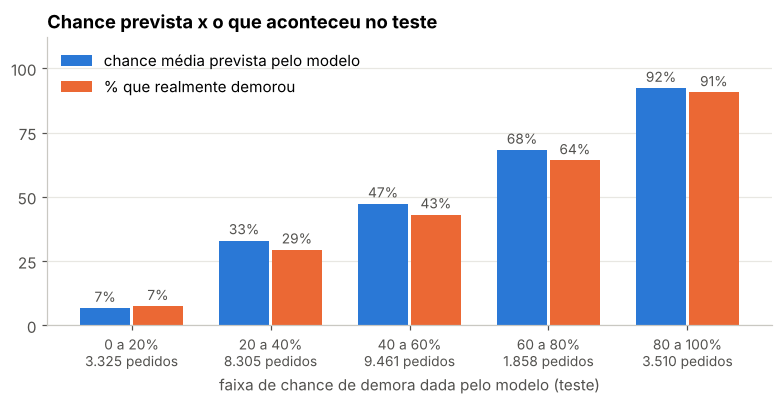

,solicitacoes,chance_media_prevista,demora_real
faixa,,,
0 a 20%,3325,0.068,0.075
20 a 40%,8305,0.330,0.294
40 a 60%,9461,0.473,0.431
60 a 80%,1858,0.682,0.642
80 a 100%,3510,0.923,0.906


In [19]:
faixas = pd.cut(prob_teste, bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True,
                labels=["0 a 20%", "20 a 40%", "40 a 60%", "60 a 80%", "80 a 100%"])
confianca = pd.DataFrame({"faixa": faixas, "prevista": prob_teste, "real": y_teste.values}).groupby("faixa", observed=True).agg(
    solicitacoes=("real", "size"), chance_media_prevista=("prevista", "mean"), demora_real=("real", "mean"))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
posicoes = np.arange(len(confianca))
barras_prev = ax.bar(posicoes - 0.19, confianca["chance_media_prevista"] * 100, 0.36, color=AZUL, label="chance média prevista pelo modelo")
barras_real = ax.bar(posicoes + 0.19, confianca["demora_real"] * 100, 0.36, color=LARANJA, label="% que realmente demorou")
for barras in (barras_prev, barras_real):
    ax.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=9, color=TEXTO)
ax.set_xticks(posicoes, [f"{f}\n{n:,} pedidos".replace(",", ".") for f, n in zip(confianca.index, confianca["solicitacoes"])], fontsize=9)
ax.set_ylim(0, 112); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("faixa de chance de demora dada pelo modelo (teste)")
ax.set_title("Chance prevista x o que aconteceu no teste")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIGURAS / "07_confianca_das_probabilidades.png")
plt.show()

confianca.astype({"chance_media_prevista": float}).round(3)

### 6.3 O que mais pesa na previsão

{'servico': 50.8, 'mes': 20.7, 'subprefeitura': 10.7, 'latitude': 7.6, 'longitude': 7.3, 'canal': 1.5, 'dia_semana': 1.4}


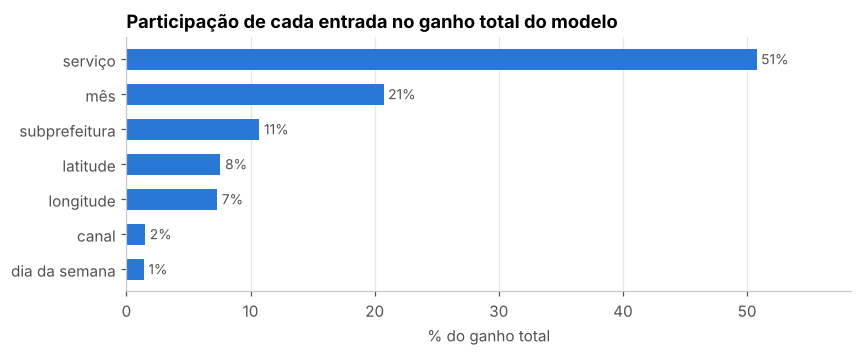

In [20]:
# Importância por ganho: quanto cada entrada ajuda a separar as classes nas árvores.
# As colunas 0/1 de uma mesma variável categórica são somadas para dar a importância da variável inteira.
ganho = pd.Series(modelo.get_booster().get_score(importance_type="total_gain"))
grupo = ganho.index.to_series().apply(lambda coluna: next((c for c in CATEGORICAS if coluna.startswith(c + "_")), coluna))
importancia = (ganho.groupby(grupo).sum() / ganho.sum() * 100).sort_values()
print(importancia.round(1).sort_values(ascending=False).to_dict())
importancia.index = importancia.index.map({"servico": "serviço", "canal": "canal", "subprefeitura": "subprefeitura",
                                           "latitude": "latitude", "longitude": "longitude", "mes": "mês",
                                           "dia_semana": "dia da semana"})

fig, ax = plt.subplots(figsize=(8.5, 3.0))
barras = ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.bar_label(barras, fmt="%.0f%%", padding=3, fontsize=9, color=TEXTO)
ax.set_xlim(0, importancia.max() * 1.15)
ax.set_title("Participação de cada entrada no ganho total do modelo")
ax.set_xlabel("% do ganho total")
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIGURAS / "08_importancia_das_entradas.png")
plt.show()

### 6.4 Leitura dos resultados e discussão de overfitting

**O modelo aprendeu algo que vale para meses que ele não viu.** No teste, a AUC é 0,767 e a acurácia é 0,706, contra 0,579 de quem sempre responde "não demora" (ganho de 12,7 pontos). A acurácia balanceada sai de 0,500 para 0,681.

**Existe overfitting, e ele é relevante.** A AUC cai de 0,909 no treino para 0,767 no teste (0,142 de diferença) e o F1 da classe "demora" cai de 0,749 para 0,599. Vemos duas causas:

1. **Árvores profundas decoram detalhes do treino.** Com profundidade 9 o modelo recorta o mapa em pedaços muito pequenos e guarda o que aconteceu em cada um.
2. **A cidade mudou de ritmo.** A taxa de demora passou de 35,8% no treino para 42,1% no teste. Parte do que o modelo aprendeu sobre 2025 não vale mais em maio e junho de 2026.

A validação cruzada estimou 0,800 e o teste deu 0,767: ela foi um aviso bem mais honesto do que a nota do treino.

**A divisão por sorteio enfeitaria o resultado.** Com os mesmos hiperparâmetros, ela daria AUC de 0,878 no teste (Seção 6.1), 0,11 a mais. Misturar dias da mesma semana no treino e no teste deixa o modelo "saber" o ritmo de cada época, coisa que o app nunca vai ter na hora de prever uma ocorrência nova. O número que vale é o da divisão por data.

**O ponto fraco é o recall (0,52).** Com corte em 50%, o modelo deixa passar quase metade das demoras. Quando ele avisa que vai demorar, acerta 7 em cada 10 vezes (precisão 0,70).

**As probabilidades são confiáveis.** Em todas as faixas, a chance média prevista fica a menos de 5 pontos percentuais do que aconteceu (Seção 6.2), com leve exagero nas faixas do meio. Por isso faz mais sentido o app mostrar faixas de chance do que um "sim" ou "não".

**O que pesa na previsão:** o serviço responde por 51% do ganho; o mês, por 21%; a região (subprefeitura, latitude e longitude), por 26%; canal e dia da semana, por cerca de 3% somados.

**Um cuidado com o mês.** Temos só 12 meses de dados, então o modelo nunca viu dois meses de maio. O peso do mês vem principalmente de ele separar o período rápido (2025) do lento (2026). Nos meses de teste (maio e junho), que não aparecem no treino, as árvores tratam o mês como "igual ou depois de abril", ou seja, repetem o ritmo mais recente que conhecem. Funcionou neste teste, mas não é sazonalidade aprendida. Para isso seriam necessários pelo menos dois anos de dados.

## 7. O que o resultado significa para o cidadão

### 7.1 Como o SmartRoad usaria o modelo

A função abaixo recebe exatamente o que o app tem quando o cidadão toca em "Registrar" e devolve a chance de demora. Para não inventar exemplos, usamos **seis solicitações reais do período de teste**, duas de cada tipo do app, e comparamos a previsão com o que de fato aconteceu.

In [21]:
def prever_demora(servico, canal, subprefeitura, latitude, longitude, data):
    # Chance (0 a 1) de uma ocorrência registrada agora demorar mais de 30 dias
    data = pd.Timestamp(data)
    linha = pd.DataFrame([{"latitude": latitude, "longitude": longitude, "mes": data.month, "dia_semana": data.dayofweek,
                           "servico": servico, "canal": canal, "subprefeitura": subprefeitura}])
    entrada = pd.get_dummies(linha, columns=CATEGORICAS, dtype=int).reindex(columns=X.columns, fill_value=0)
    return float(modelo.predict_proba(entrada)[0, 1])

def mensagem_para_o_cidadao(chance):
    if chance < 0.4:
        return "Pedidos como este costumam ser finalizados em até 30 dias."
    if chance < 0.6:
        return "Não dá para afirmar: pedidos como este ficam perto de meio a meio."
    return "Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app."

# Duas solicitações reais do teste para cada tipo do SmartRoad (sorteadas com a mesma semente)
teste = dados[~no_treino]
exemplos = teste.groupby("tipo_smartroad").sample(2, random_state=SEMENTE)

linhas = []
for _, e in exemplos.iterrows():
    chance = prever_demora(e["servico"], e["canal"], e["subprefeitura"], e["latitude"], e["longitude"], e["data_abertura"])
    aconteceu = "ainda aberta na extração" if pd.isna(e["dias_ate_finalizar"]) else f"finalizada em {e['dias_ate_finalizar']:.0f} dia(s)"
    linhas.append({"tipo no app": e["tipo_smartroad"], "serviço SP156": NOME_CURTO[e["servico"]],
                   "subprefeitura": e["subprefeitura"].title(), "aberta em": f"{e['data_abertura']:%d/%m/%Y}",
                   "chance de demora": f"{chance:.0%}", "mensagem no app": mensagem_para_o_cidadao(chance),
                   "o que aconteceu": aconteceu})
pd.DataFrame(linhas)

,tipo no app,serviço SP156,subprefeitura,aberta em,chance de demora,mensagem no app,o que aconteceu
0,Bueiro,Limpeza de bueiro e boca de lobo,Campo Limpo,31/05/2026,6%,Pedidos como este costumam ser finalizados em até 30 dias.,finalizada em 1 dia(s)
1,Bueiro,Limpeza de bueiro e boca de lobo,Ipiranga,24/06/2026,1%,Pedidos como este costumam ser finalizados em até 30 dias.,finalizada em 2 dia(s)
2,Buraco,Tapa-buraco,Santo Amaro,13/05/2026,41%,Não dá para afirmar: pedidos como este ficam perto de meio a meio.,finalizada em 6 dia(s)
3,Buraco,Tapa-buraco,Ipiranga,29/06/2026,58%,Não dá para afirmar: pedidos como este ficam perto de meio a meio.,ainda aberta na extração
4,Calçada,Calçada pública: manutenção,Santo Amaro,16/05/2026,41%,Não dá para afirmar: pedidos como este ficam perto de meio a meio.,finalizada em 18 dia(s)
5,Calçada,Calçada particular danificada,Jacana-Tremembe,05/05/2026,76%,Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app.,finalizada em 50 dia(s)


### 7.2 O modelo acerta o retrato de cada tipo de ocorrência?

In [22]:
# No teste: chance média prevista x demora real, por tipo do SmartRoad
retrato = teste.assign(chance_prevista=prob_teste).groupby("tipo_smartroad").agg(
    solicitacoes=("demora", "size"), chance_media_prevista=("chance_prevista", "mean"), demora_real=("demora", "mean"))
retrato[["chance_media_prevista", "demora_real"]] = (retrato[["chance_media_prevista", "demora_real"]].astype(float) * 100).round(1)
display(retrato)

# E as três mensagens do app: quantas vezes cada uma apareceria no teste e o que aconteceu de fato
por_mensagem = pd.DataFrame({"mensagem": [mensagem_para_o_cidadao(p) for p in prob_teste], "demora": y_teste.values}).groupby("mensagem").agg(
    solicitacoes=("demora", "size"), demora_real=("demora", "mean")).sort_values("demora_real")
por_mensagem["% do teste"] = (por_mensagem["solicitacoes"] / len(y_teste) * 100).round(1)
por_mensagem["demora_real"] = (por_mensagem["demora_real"] * 100).round(1)
por_mensagem

,solicitacoes,chance_media_prevista,demora_real
tipo_smartroad,,,
Bueiro,4914,27.7,24.3
Buraco,14754,39.5,35.8
Calçada,6791,70.1,68.6


,solicitacoes,demora_real,% do teste
mensagem,,,
Pedidos como este costumam ser finalizados em até 30 dias.,11630,23.1,44.0
Não dá para afirmar: pedidos como este ficam perto de meio a meio.,9461,43.1,35.8
Pedidos como este costumam passar de 30 dias. Vale acompanhar pelo app.,5368,81.4,20.3


### 7.3 Conclusão

**Resposta à pergunta.** Sim, em parte. Só com o que o SmartRoad sabe no momento do registro, o modelo separa os pedidos que tendem a demorar dos que tendem a ser finalizados em até 30 dias melhor do que o acaso e do que a linha de base (AUC de 0,77 e acurácia de 0,71 em dois meses que ele não viu). Ele não acerta caso a caso: é uma estimativa de chance.

**O que isso significa para o cidadão**

- **Expectativa honesta já no registro.** Hoje quem registra um buraco só vê "Recebida". Com o modelo, o app pode dizer na hora o que costuma acontecer com pedidos parecidos. No teste, a mensagem "costumam ser finalizados em até 30 dias" apareceria em 44% dos pedidos, e 77% deles foram mesmo finalizados no prazo. A mensagem "costumam passar de 30 dias" apareceria em 20% dos pedidos, e 81% deles de fato passaram.
- **O modelo também sabe dizer "não sei".** Em 36% dos pedidos a chance fica perto de meio a meio. Nesses casos o app deve dizer isso com clareza, em vez de prometer um prazo.
- **O tipo de problema pesa mais que tudo.** No teste, 24% dos pedidos de bueiro, 36% dos de buraco e 69% dos de calçada passaram de 30 dias. Quem depende de calçada em bom estado (idosos, pessoas com deficiência, quem anda com carrinho de bebê) é quem mais espera.
- **O endereço também pesa.** No período analisado, a taxa de demora foi de 22% em Perus e Ermelino Matarazzo e de 50% na Sé. O mesmo pedido tem espera diferente conforme a região. Mostrar isso ajuda moradores e associações de bairro a cobrar com dados, o que liga o projeto aos ODS 11 (cidades sustentáveis) e 10 (redução das desigualdades).

**Limites que o cidadão e a equipe precisam conhecer**

- "Finalizada" no SP156 quer dizer que o órgão encerrou o protocolo. Os dados não dizem se o reparo foi feito nem se ficou bom.
- O modelo aprendeu com 12 meses, e o ritmo da Prefeitura mudou no meio do caminho. Ele precisa ser retreinado com frequência (por exemplo, todo mês) e reavaliado sempre em meses futuros.
- Ele deixa passar quase metade das demoras (recall de 0,52). Serve para dar expectativa, não para garantir prazo.
- O SP156 não publica a gravidade, a foto nem a descrição do pedido, que o SmartRoad coleta. Também não traz iluminação pública. E o número de solicitações não é o número de problemas: várias pessoas podem pedir o mesmo reparo.

**Próximos passos**

1. Usar dois ou mais anos de SP156 para o modelo aprender a época do ano de verdade.
2. Juntar a chuva diária do INMET e testar se ela explica parte da demora.
3. Incluir a fila de pedidos em aberto de cada subprefeitura como entrada.
4. Servir a função `prever_demora` pelo backend do SmartRoad para a tela "Detalhe da ocorrência".